In [1]:
import numpy as np 
data = np.load('cifar-10-python.npz')

In [2]:
data

NpzFile 'cifar-10-python.npz' with keys: x_test, x_train, y_train, y_test

In [3]:
train_image = data['x_train']
test_image = data['x_test']
train_labels = data['y_train']
test_labels = data['y_test']

In [4]:
print(train_image.shape)
print(test_image.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [5]:
print(train_labels)


[6 9 9 ... 9 1 1]


In [6]:
train_image_normal = train_image / 255
test_image_normal = test_image / 255

[[[0.83529412 0.89803922 0.94901961]
  [0.82745098 0.89019608 0.94117647]
  [0.82745098 0.89019608 0.94117647]
  ...
  [0.59215686 0.68235294 0.80784314]
  [0.59215686 0.68235294 0.80784314]
  [0.58431373 0.6745098  0.8       ]]

 [[0.83921569 0.89803922 0.94509804]
  [0.83137255 0.89019608 0.9372549 ]
  [0.83137255 0.89019608 0.9372549 ]
  ...
  [0.59607843 0.68627451 0.81176471]
  [0.59607843 0.68627451 0.81176471]
  [0.59215686 0.68235294 0.80392157]]

 [[0.84705882 0.89803922 0.9372549 ]
  [0.83921569 0.89019608 0.92941176]
  [0.83529412 0.89019608 0.92941176]
  ...
  [0.6        0.69019608 0.80784314]
  [0.6        0.69019608 0.80784314]
  [0.59215686 0.68235294 0.8       ]]

 ...

 [[0.56862745 0.62352941 0.64705882]
  [0.53333333 0.58039216 0.60392157]
  [0.56078431 0.59607843 0.61960784]
  ...
  [0.84705882 0.85098039 0.80784314]
  [0.76862745 0.77254902 0.74901961]
  [0.71764706 0.71764706 0.71372549]]

 [[0.54509804 0.6        0.62352941]
  [0.50588235 0.55686275 0.58039216]


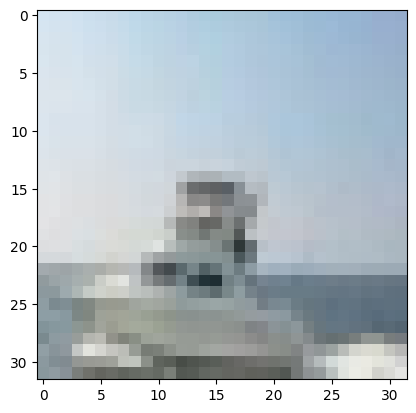

In [7]:
import matplotlib.pyplot as plt
class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']


a = 100
print(train_image_normal[a])
plt.imshow(train_image_normal[a])

In [8]:
train_image_flat = train_image_normal.reshape(-1 , 3072)
test_image_flat = test_image_normal.reshape(-1 , 3072)
### midoonam braye kenar ham chidan dade has ama chejury rabete 5000 ba 3073 chye


In [9]:
train_image_flat.shape

(50000, 3072)

In [10]:
from keras.models import Sequential
from keras.layers import Dense , Input , Activation

MLP = Sequential()

MLP.add(Input(shape=(3072 ,)))

MLP.add(Dense(256))
MLP.add(Activation('relu'))

MLP.add(Dense(128))
MLP.add(Activation('relu'))

MLP.add(Dense(64))
MLP.add(Activation('relu'))

MLP.add(Dense(10,activation='softmax'))

In [11]:
MLP.compile(optimizer='adam' , loss='sparse_categorical_crossentropy' , metrics=['accuracy'])

In [12]:
MLP.fit(
    train_image_flat,
    train_labels,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - accuracy: 0.3123 - loss: 1.8959 - val_accuracy: 0.3548 - val_loss: 1.7856
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.3854 - loss: 1.7098 - val_accuracy: 0.3845 - val_loss: 1.7016
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.4166 - loss: 1.6330 - val_accuracy: 0.4132 - val_loss: 1.6497
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.4346 - loss: 1.5830 - val_accuracy: 0.4061 - val_loss: 1.6321
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.4502 - loss: 1.5320 - val_accuracy: 0.4403 - val_loss: 1.5808
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 16ms/step - accuracy: 0.4614 - loss: 1.5053 - val_accuracy: 0.4501 - val_loss: 1.5554
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.4701 - loss: 1.4785 - val_accuracy: 0.4646 - val_loss: 1.5157
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.4822 -

In [13]:
print(MLP.input_shape)

(None, 3072)


In [19]:
import cv2
img = cv2.imread('test.png')
img= cv2.resize(img,(32 ,32))
img = cv2.cvtColor(img , cv2.COLOR_BGR2RGB)
img = img / 255.0
img = img.reshape(1 ,32 , 32 , 3)
img = img.reshape(1 , 3072)
y_pred = MLP.predict(img)
y = np.argmax(y_pred)
print(y,class_names[y])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2 bird


In [15]:
from keras.layers import Conv2D , MaxPooling2D , Flatten

CNN = Sequential()
CNN.add(Input(shape=(32 , 32 , 3)))
CNN.add(Conv2D(32 ,(3,3) ,activation='relu'))
CNN.add(MaxPooling2D((2,2)))
CNN.add(Flatten())
CNN.add(Dense(128 , activation='relu'))
CNN.add(Dense(10 , activation='softmax'))
               

In [16]:
CNN.compile(optimizer='adam' , loss='sparse_categorical_crossentropy' , metrics=['accuracy'])


In [17]:
hCNN = CNN.fit(train_image_normal , train_labels , epochs=50 , batch_size=128)

Epoch 1/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 15s 32ms/step - accuracy: 0.4312 - loss: 1.6007
Epoch 2/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.5540 - loss: 1.2678
Epoch 3/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.6011 - loss: 1.1406
Epoch 4/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.6285 - loss: 1.0679
Epoch 5/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.6526 - loss: 1.0059
Epoch 6/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.6705 - loss: 0.9525
Epoch 7/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.6897 - loss: 0.9036
Epoch 8/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7001 - loss: 0.8682
Epoch 9/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.7088 - loss: 0.8441
Epoch 10/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.7246 - loss: 0.7993
Epoch 11/50
391/391 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.7318 - loss: 0.7722
Epoch 12/50
391/391 ━━━━━━━━━━

In [22]:
import cv2
img = cv2.imread('horse.png')
img= cv2.resize(img,(32 ,32))
img = cv2.cvtColor(img , cv2.COLOR_BGR2RGB)
img = img / 255.0
img = img.reshape(1 ,32 , 32 , 3)
p_pred = CNN.predict(img)
p = np.argmax(p_pred)
print(p,class_names[p])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
7 horse
